## Calculation Method

To transform the particle shower coordinates into a shower-fixed local coordinate system, two main steps are required: first, translating the shower's impact point to the origin, and then spatially rotating the coordinate system to align the new $z'$-axis with the shower's incident direction.

### 1. Translation

The initial step involves defining the shower's origin, $P_0 = (x_0, y_0, z_0)$. This origin is typically chosen as the energy-weighted centroid of the first detector layer where the particle interacts. The coordinates of each energy deposition $(x, y, z)$ are then translated by subtracting this origin, effectively moving the shower's starting point to $(0,0,0)$ in the translated system:

$$\Delta x = x - x_0$$
$$\Delta y = y - y_0$$
$$\Delta z = z - z_0$$

### 2. Rotation

The direction of the incident particle, and thus the shower axis, is characterized by two angles: $\theta$ (the polar angle with respect to the Z-axis) and $\phi$ (the azimuthal angle in the X-Y plane). The coordinate system must then be rotated so that the new $z'$-axis is precisely aligned with this incident direction.

This transformation is achieved using a rotation matrix ($R$). This matrix can be conceptualized as two sequential rotations: a rotation by angle $\phi$ around the original Z-axis, followed by a rotation by angle $\theta$ around the new Y-axis. The composite rotation matrix is given by:

$$R = \begin{pmatrix} \cos\theta \cos\phi & \cos\theta \sin\phi & -\sin\theta \\ -\sin\phi & \cos\phi & 0 \\ \sin\theta \cos\phi & \sin\theta \sin\phi & \cos\theta \end{pmatrix}$$

The new, shower-fixed coordinates $(x', y', z')$ are obtained by multiplying this rotation matrix by the translated position vector:

$$\begin{pmatrix} x' \\ y' \\ z' \end{pmatrix} = \begin{pmatrix} \cos\theta \cos\phi & \cos\theta \sin\phi & -\sin\theta \\ -\sin\phi & \cos\phi & 0 \\ \sin\theta \cos\phi & \sin\theta \sin\phi & \cos\theta \end{pmatrix} \begin{pmatrix} \Delta x \\ \Delta y \\ \Delta z \end{pmatrix}$$

### The Final Equations

Expanding the matrix multiplication, the new coordinates of the energy depositions in the shower's own local coordinate system are:

*   **$x'$ (transverse coordinate 1):** Represents one of the transverse dimensions perpendicular to the shower axis.
    $$x' = \Delta x \cdot \cos\theta \cos\phi + \Delta y \cdot \cos\theta \sin\phi - \Delta z \cdot \sin\theta$$

*   **$y'$ (transverse coordinate 2):** Represents the other transverse dimension, also perpendicular to the shower axis.
    $$y' = -\Delta x \cdot \sin\phi + \Delta y \cdot \cos\phi$$

*   **$z'$ (longitudinal depth along the shower):** Represents the depth of energy deposition along the main axis of the particle shower.
    $$z' = \Delta x \cdot \sin\theta \cos\phi + \Delta y \cdot \sin\theta \sin\phi + \Delta z \cdot \cos\theta$$



**Interpretation of the Transformation Result:**
In this new local system, the $z'$ coordinate directly indicates the depth at which energy deposition occurred, measured from the shower's initial interaction point along its propagation direction. The $x'$ and $y'$ coordinates describe the lateral spread of the shower perpendicular to its axis. These can be used to calculate the radial distance from the shower axis ($r = \sqrt{x'^2 + y'^2}$), which is a key metric for analyzing the transverse profile and overall shape of the shower, independent of its initial entry point and angle in the detector.

In [1]:
import os
os.chdir('..')

import core

2026-09-21 16:41:51.739366: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-21 16:41:51.781905: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-21 16:41:52.683054: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
file = '../data/simulations/regression-proton/proton_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv'

In [3]:
df = core.pd.read_csv(file)

In [4]:
df["z"] = df["z"] - core.SHIFT_Z
print("X", int(round(df["x"].min(), 0)), int(round(df["x"].max(), 0)))
print("Y", int(round(df["y"].min(), 0)), int(round(df["y"].max(), 0)))
print("Z", int(round(df["z"].min(), 0)), int(round(df["z"].max(), 0)))
df.head(5)

X -2596 2601
Y -2600 2600
Z 13 1223


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,186640,2823563636,-1387.531982,-2147.199951,730.899902,-130.723225,-378.459188,761.351211,-463.007620,-103.890706,...,4.238810e-08,1200.353271,17.044954,0.549644,-1.997623,17,neutron,1,neutron,gamma;gamma
1,132450,163584116,132.927994,2551.199951,628.399902,69.697194,210.840800,750.914462,-152.802091,460.011513,...,6.959773e-08,574.963501,13.259551,0.524659,1.441496,13,neutron,1,neutron,proton;proton
2,1436,2307335028,-830.135010,-175.800003,710.399902,-226.855893,-0.924198,665.431786,90.170637,18.004689,...,6.916019e-04,14.909340,16.654422,0.197399,-2.954562,16,proton,1,neutron,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,118990,608834164,835.135010,-1339.199951,238.899902,-119.737264,179.827552,193.795084,146.963886,108.548892,...,1.211111e-08,1620.073486,19.433977,0.411175,-1.112347,19,neutron,1,neutron,NaN
4,49113,4412592500,984.348999,1440.199951,587.399902,-218.178821,-147.723526,531.631196,141.541496,-50.457615,...,2.290001e-05,165.507782,17.042273,0.437355,1.044127,17,neutron,1,neutron,gamma;gamma;gamma


In [6]:
df[['incoming_theta', 'incoming_phi', 
    'x', 'y', 'z', 
    'x_local', 'y_local', 'z_local', 
    'x_trans', 'y_trans', 'z_trans']].describe()

,incoming_theta,incoming_phi,x,y,z,x_local,y_local,z_local,x_trans,y_trans,z_trans
count,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07,5.474055e+07
mean,4.006501e-01,8.350184e-05,8.340518e+00,-3.721223e+00,4.387545e+02,-4.207020e+01,1.054415e-01,4.406571e+02,6.120635e-02,3.625353e-03,4.246412e+02
std,1.346250e-01,1.805050e+00,1.308310e+03,1.311835e+03,2.839532e+02,2.241171e+02,2.235098e+02,3.025983e+02,2.520863e+02,2.520673e+02,2.833617e+02
min,5.243455e-02,-3.141428e+00,-2.596035e+03,-2.599800e+03,1.339990e+01,-4.896420e+03,-3.319625e+03,-2.931879e+03,-4.887696e+03,-4.894655e+03,0.000000e+00
25%,3.022523e-01,-1.558525e+00,-1.032024e+03,-1.036200e+03,2.183999e+02,-1.444550e+02,-1.091375e+02,2.039936e+02,-1.398834e+02,-1.405741e+02,2.050000e+02
50%,4.191639e-01,5.972076e-04,3.040900e+01,-2.620000e+01,3.823999e+02,-3.088325e+01,0.000000e+00,3.921629e+02,0.000000e+00,0.000000e+00,3.690000e+02
75%,5.111207e-01,1.558250e+00,1.041428e+03,1.036200e+03,6.283999e+02,6.947679e+01,1.090265e+02,6.374536e+02,1.412087e+02,1.403782e+02,6.150000e+02
max,6.283148e-01,3.141572e+00,2.601035e+03,2.599800e+03,1.222900e+03,2.979718e+03,3.238695e+03,2.667495e+03,5.140408e+03,5.147369e+03,1.209500e+03


Average number of hits in an event: 547.4


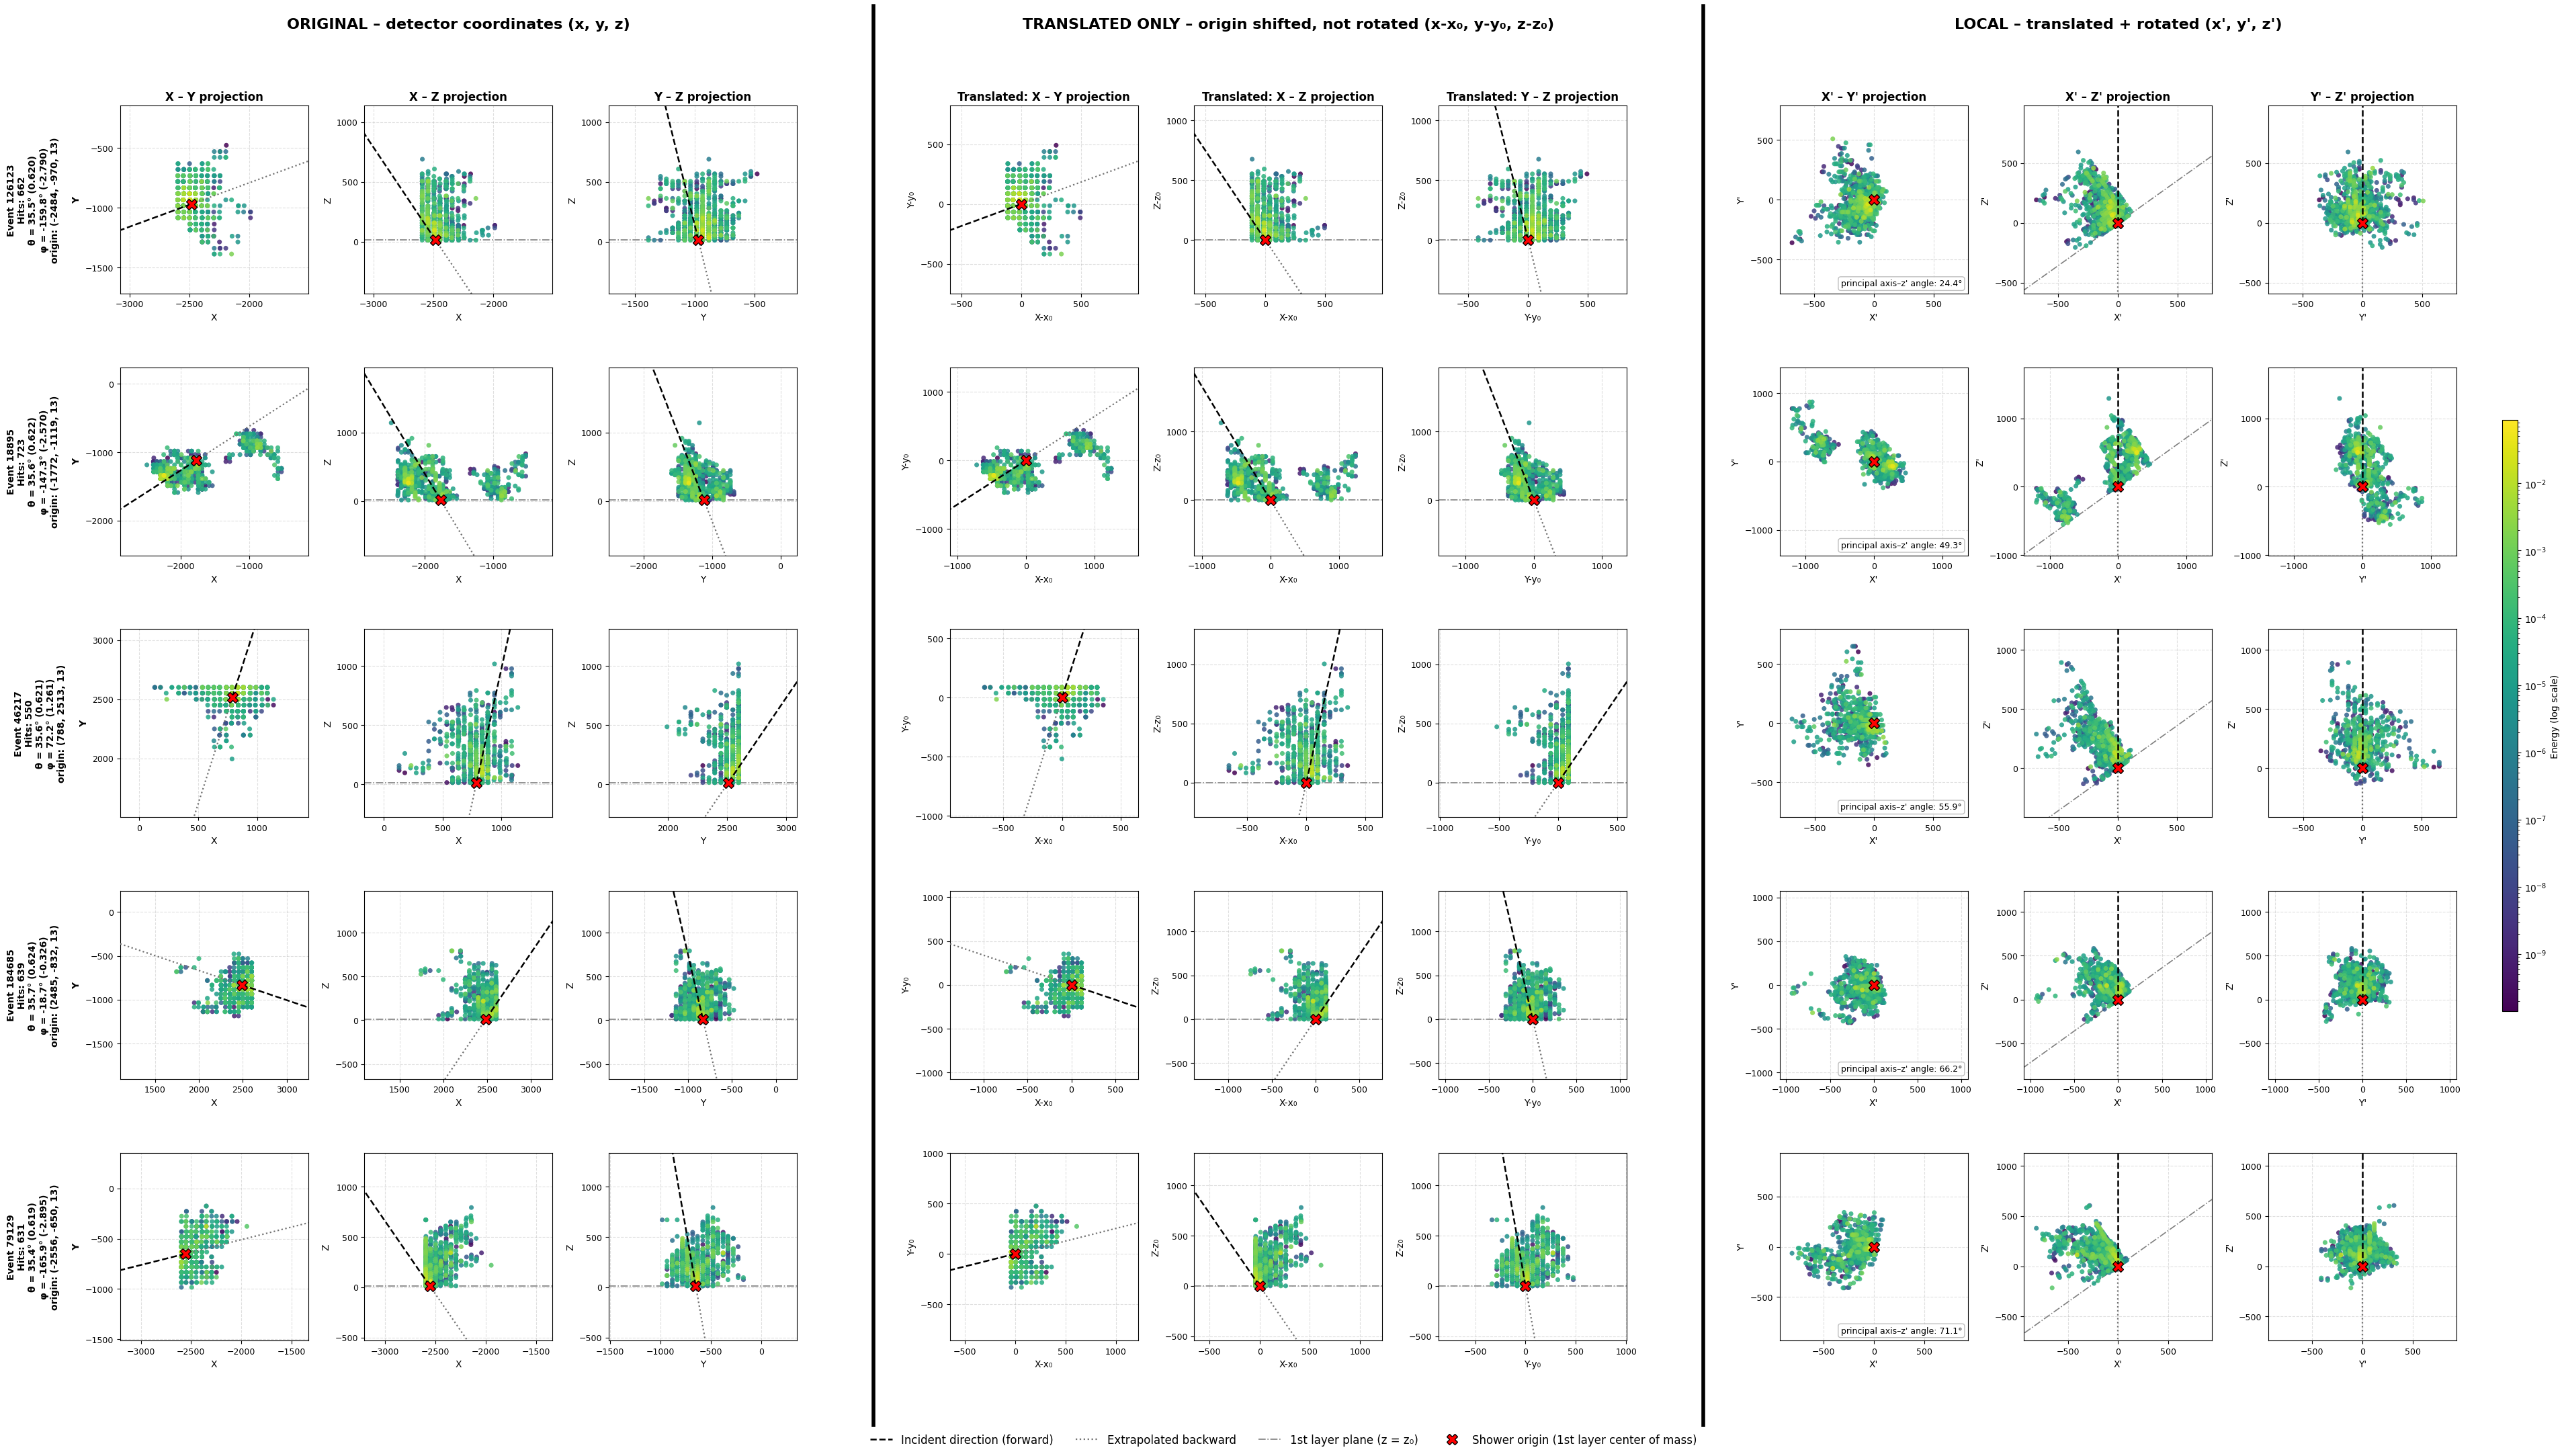

In [8]:
# @title Visualize by showers (original / translated / local)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

REQUIRED_COLUMNS = {
    'event_number', 'x', 'y', 'z', 'energy',
    'incoming_theta', 'incoming_phi',
    'x_local', 'y_local', 'z_local',
}


# ----------------------------------------------------------------------------
# Helper Functions
# ----------------------------------------------------------------------------
def _select_events(df, n_events, top_pool_size, seed):
    """Selects from events with above-average hits from the pool with the largest theta."""
    grouped = df.groupby('event_number')
    hit_counts = grouped.size()
    angles = grouped[['incoming_theta', 'incoming_phi']].first()
    mean_hits = hit_counts.mean()
    print(f"Average number of hits in an event: {mean_hits:.1f}")

    dense = angles[hit_counts > mean_hits]
    pool = (dense.sort_values('incoming_theta', ascending=False)
                 .head(top_pool_size).index.to_numpy())
    if len(pool) == 0:
        return []
    rng = np.random.default_rng(seed)
    return rng.choice(pool, size=min(n_events, len(pool)), replace=False).tolist()


def _principal_axis_tilt_deg(xl, yl, zl, w):
    """Angle between the principal axis of the energy-weighted hit cloud and the z' axis (degrees)."""
    pts = np.column_stack([xl, yl, zl])
    d = pts - np.average(pts, axis=0, weights=w)
    cov = (d * w[:, None]).T @ d / w.sum()
    _, vecs = np.linalg.eigh(cov)                  # ascending eigenvalues
    return np.degrees(np.arccos(np.clip(abs(vecs[2, -1]), 0.0, 1.0)))


def _scatter(ax, u, v, e, norm, cmap):
    """Draws sorted by energy, so high-energy hits are on top."""
    order = np.argsort(e)
    return ax.scatter(u[order], v[order], c=np.clip(e[order], norm.vmin, None),
                      cmap=cmap, norm=norm, s=26, alpha=0.85, linewidths=0, zorder=2)


def _style(ax, xlim, ylim, xlabel, ylabel):
    ax.set(xlim=xlim, ylim=ylim, xlabel=xlabel, ylabel=ylabel)
    ax.set_aspect('equal', adjustable='box')      # tilt is visible at true angle
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.locator_params(nbins=5)
    ax.tick_params(labelsize=9)


def _draw_direction(ax, p, d, L):
    """From point p in direction d: dashed forward, dotted backward line."""
    ax.plot([p[0], p[0] + L * d[0]], [p[1], p[1] + L * d[1]],
            color='black', ls='--', lw=1.8, zorder=3)
    ax.plot([p[0], p[0] - L * d[0]], [p[1], p[1] - L * d[1]],
            color='0.45', ls=':', lw=1.6, zorder=3)


# ----------------------------------------------------------------------------
# Main Function
# ----------------------------------------------------------------------------
def visualize_transformation_check(df, n_events=5, top_pool_size=20, events=None,
                                   seed=None, pad=1.15, min_half=150, cmap='viridis'):
    """
    Comparison of original (x, y, z), translated-only (x-x0, y-y0, z-z0) and
    shower-fixed / rotated (x', y', z') coordinates.

    The "translated" panel shows the intermediate step: the hit cloud shifted
    so that the shower origin sits at (0, 0, 0), but WITHOUT the rotation that
    aligns the shower axis with z'. Comparing it to the original and to the
    fully local (translated + rotated) panels makes the effect of the
    translation and of the rotation separately visible.

    events : specific event_number list (e.g., [105520]); if None, automatic selection.
    seed   : to make automatic selection reproducible.
    pad    : window margin multiplier (1.15 = 15%).
    Returns the list of displayed event_numbers.
    """
    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise KeyError(f"Missing columns: {sorted(missing)}")

    selected = list(events) if events is not None else _select_events(
        df, n_events, top_pool_size, seed)
    if not selected:
        print("No matching events found in the database.")
        return []

    sub = df[df['event_number'].isin(selected)]
    groups = {k: g for k, g in sub.groupby('event_number')}
    selected = [ev for ev in selected if ev in groups]
    if not selected:
        print("Specified events not found in the database.")
        return []
    n = len(selected)

    # Common logarithmic color scale for all panels (original, translated, local)
    e_pos = sub.loc[sub['energy'] > 0, 'energy'].to_numpy()
    norm = LogNorm(vmin=np.percentile(e_pos, 1), vmax=e_pos.max())

    # --- Figure Layout (3 groups of 3 columns = 9 columns total) ----------
    fig = plt.figure(figsize=(38, 4.2 * n + 1))
    kw = dict(top=0.92, bottom=0.07, wspace=0.30, hspace=0.25)
    gs_o = gridspec.GridSpec(n, 3, left=0.045, right=0.310, **kw)   # original
    gs_t = gridspec.GridSpec(n, 3, left=0.370, right=0.635, **kw)   # translated
    gs_l = gridspec.GridSpec(n, 3, left=0.695, right=0.960, **kw)   # local (rotated)

    marker = dict(marker='X', color='red', markeredgecolor='black',
                  markersize=12, linestyle='none', zorder=5)

    def col_title(ax, i, text):
        if i == 0:
            ax.set_title(text, fontweight='bold', fontsize=12)

    for i, event_id in enumerate(selected):
        evt = groups[event_id]
        x, y, z, xl, yl, zl, e = (evt[c].to_numpy(dtype=float) for c in
                                  ('x', 'y', 'z', 'x_local', 'y_local', 'z_local', 'energy'))
        theta = float(evt['incoming_theta'].iloc[0])
        phi = float(evt['incoming_phi'].iloc[0])
        st, ct, sp, cp = np.sin(theta), np.cos(theta), np.sin(phi), np.cos(phi)
        nvec = np.array([st * cp, st * sp, ct])       # shower propagation direction

        # Origin: energy-weighted center of mass of the first layer
        z0 = z.min()
        m = z == z0
        x0 = np.average(x[m], weights=e[m])
        y0 = np.average(y[m], weights=e[m])

        # Translated-only coordinates: shift origin to (0,0,0), no rotation
        xt, yt, zt = x - x0, y - y0, z - z0

        tilt = _principal_axis_tilt_deg(xl, yl, zl, e)

        # --- Event-specific window: all panels same size, equal aspect ---
        half = 0.5 * max(np.ptp(a) for a in (x, y, z, xl, yl, zl))
        half = max(half, np.abs(xl).max(), np.abs(yl).max())
        half = max(half * pad, min_half)
        L = 100 * half                                 # "infinite" long line, clipped by window

        mid = lambda a: 0.5 * (a.max() + a.min())
        win = lambda c: (c - half, c + half)
        xlim, ylim, zlim = win(mid(x)), win(mid(y)), win(mid(z))
        xtlim, ytlim, ztlim = win(mid(xt)), win(mid(yt)), win(mid(zt))
        lim0, zlim_l = win(0.0), win(mid(zl))

        row_label = (f"Event {event_id}\nHits: {len(evt)}\n"
                     f"θ = {np.degrees(theta):.1f}° ({theta:.3f})\n"
                     f"φ = {np.degrees(phi):.1f}° ({phi:.3f})\n"
                     f"origin: ({x0:.0f}, {y0:.0f}, {z0:.0f})")

        # ================= ORIGINAL =================
        # 1. X - Y
        ax = fig.add_subplot(gs_o[i, 0])
        _scatter(ax, x, y, e, norm, cmap)
        _draw_direction(ax, (x0, y0), (nvec[0], nvec[1]), L)
        ax.plot(x0, y0, **marker)
        _style(ax, xlim, ylim, 'X', 'Y')
        ax.set_ylabel(row_label + '\n\nY', fontweight='bold', fontsize=10)
        col_title(ax, i, 'X – Y projection')

        # 2. X - Z
        ax = fig.add_subplot(gs_o[i, 1])
        _scatter(ax, x, z, e, norm, cmap)
        ax.axhline(z0, color='0.5', ls='-.', lw=1.2, zorder=1)          # plane of 1st layer
        _draw_direction(ax, (x0, z0), (nvec[0], nvec[2]), L)
        ax.plot(x0, z0, **marker)
        _style(ax, xlim, zlim, 'X', 'Z')
        col_title(ax, i, 'X – Z projection')

        # 3. Y - Z
        ax = fig.add_subplot(gs_o[i, 2])
        _scatter(ax, y, z, e, norm, cmap)
        ax.axhline(z0, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (y0, z0), (nvec[1], nvec[2]), L)
        ax.plot(y0, z0, **marker)
        _style(ax, ylim, zlim, 'Y', 'Z')
        col_title(ax, i, 'Y – Z projection')

        # ================= TRANSLATED (no rotation) =================
        # 4. Xt - Yt
        ax = fig.add_subplot(gs_t[i, 0])
        _scatter(ax, xt, yt, e, norm, cmap)
        _draw_direction(ax, (0, 0), (nvec[0], nvec[1]), L)
        ax.plot(0, 0, **marker)
        _style(ax, xtlim, ytlim, "X-x₀", "Y-y₀")
        col_title(ax, i, 'Translated: X – Y projection')

        # 5. Xt - Zt
        ax = fig.add_subplot(gs_t[i, 1])
        _scatter(ax, xt, zt, e, norm, cmap)
        ax.axhline(0.0, color='0.5', ls='-.', lw=1.2, zorder=1)         # plane of 1st layer (z=0 now)
        _draw_direction(ax, (0, 0), (nvec[0], nvec[2]), L)
        ax.plot(0, 0, **marker)
        _style(ax, xtlim, ztlim, "X-x₀", "Z-z₀")
        col_title(ax, i, 'Translated: X – Z projection')

        # 6. Yt - Zt
        ax = fig.add_subplot(gs_t[i, 2])
        _scatter(ax, yt, zt, e, norm, cmap)
        ax.axhline(0.0, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (0, 0), (nvec[1], nvec[2]), L)
        ax.plot(0, 0, **marker)
        _style(ax, ytlim, ztlim, "Y-y₀", "Z-z₀")
        col_title(ax, i, 'Translated: Y – Z projection')

        # ================= LOCAL (translated + rotated) =================
        # 7. X' - Y'   (shower axis here is a single point: the origin)
        ax = fig.add_subplot(gs_l[i, 0])
        _scatter(ax, xl, yl, e, norm, cmap)
        ax.plot(0, 0, **marker)
        _style(ax, lim0, lim0, "X'", "Y'")
        ax.text(0.97, 0.03, f"principal axis–z' angle: {tilt:.1f}°", transform=ax.transAxes,
                ha='right', va='bottom', fontsize=9,
                bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.85))
        col_title(ax, i, "X' – Y' projection")

        # 8. X' - Z'   (plane of 1st layer here is the line z' = tanθ · x')
        ax = fig.add_subplot(gs_l[i, 1])
        _scatter(ax, xl, zl, e, norm, cmap)
        xs = np.array([-L, L])
        ax.plot(xs, np.tan(theta) * xs, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (0, 0), (0, 1), L)                          # z' axis
        ax.plot(0, 0, **marker)
        _style(ax, lim0, zlim_l, "X'", "Z'")
        col_title(ax, i, "X' – Z' projection")

        # 9. Y' - Z'
        ax = fig.add_subplot(gs_l[i, 2])
        _scatter(ax, yl, zl, e, norm, cmap)
        _draw_direction(ax, (0, 0), (0, 1), L)
        ax.plot(0, 0, **marker)
        _style(ax, lim0, zlim_l, "Y'", "Z'")
        col_title(ax, i, "Y' – Z' projection")

    # --- Group Headers, Separators, Legend, Colorbar -----------------------
    fig.text(0.1775, 0.965, 'ORIGINAL – detector coordinates (x, y, z)',
             ha='center', fontsize=16, fontweight='bold')
    fig.text(0.5025, 0.965, 'TRANSLATED ONLY – origin shifted, not rotated (x-x₀, y-y₀, z-z₀)',
             ha='center', fontsize=16, fontweight='bold')
    fig.text(0.8275, 0.965, "LOCAL – translated + rotated (x', y', z')",
             ha='center', fontsize=16, fontweight='bold')

    for xline in (0.340, 0.665):
        fig.add_artist(Line2D([xline, xline], [0.02, 0.98], transform=fig.transFigure,
                              color='black', linewidth=4, zorder=10))

    handles = [
        Line2D([], [], color='black', ls='--', lw=1.8, label='Incident direction (forward)'),
        Line2D([], [], color='0.45', ls=':', lw=1.6, label='Extrapolated backward'),
        Line2D([], [], color='0.5', ls='-.', lw=1.2, label='1st layer plane (z = z₀)'),
        Line2D([], [], marker='X', color='red', markeredgecolor='black', ls='none',
               markersize=11, label='Shower origin (1st layer center of mass)'),
    ]
    fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=12, frameon=False)

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cax = fig.add_axes([0.978, 0.30, 0.006, 0.40])
    fig.colorbar(sm, cax=cax, label='Energy (log scale)')

    plt.show()
    return selected


ids = visualize_transformation_check(df, seed=42)          # reproducible selection
# visualize_transformation_check(df, events=[105520])        # specific event(s)

/tmp/ipykernel_921502/1509011127.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('event_number', group_keys=False).apply(per_event)


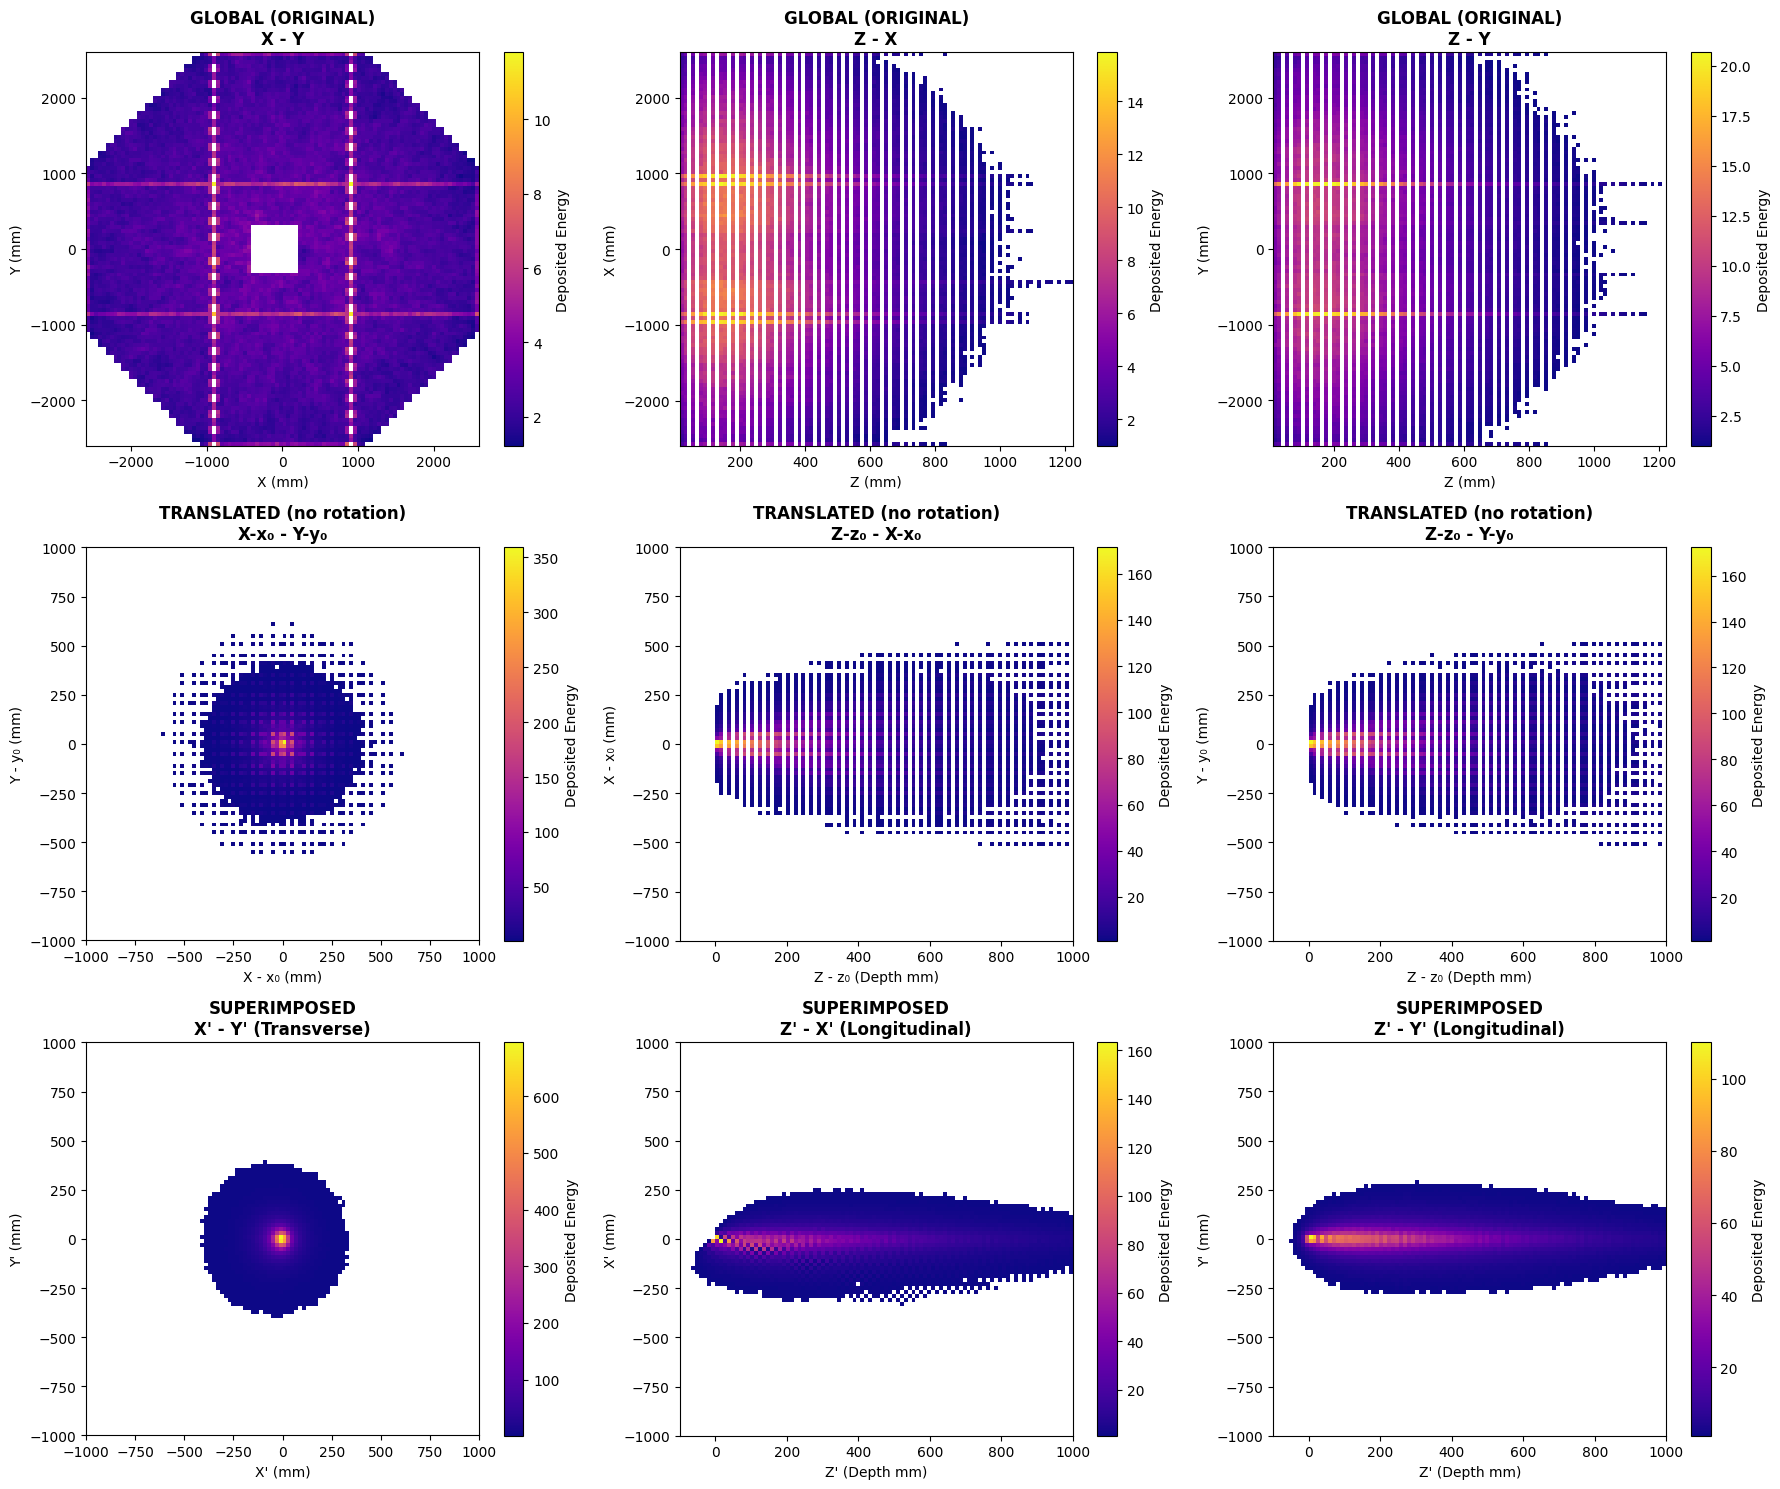

In [9]:
#@title Visualize global vs translated vs superimposed
import matplotlib.pyplot as plt
import numpy as np


def _add_translated_coords(df):
    """
    Adds x_trans, y_trans, z_trans columns: each event's hits shifted so that
    the shower origin (energy-weighted centroid of the first layer, per event)
    sits at (0, 0, 0) -- WITHOUT any rotation. This is the intermediate step
    between the global (original) and the superimposed/local (translated +
    rotated) coordinates.
    """
    def per_event(g):
        z0 = g['z'].min()
        m = g['z'] == z0
        x0 = np.average(g.loc[m, 'x'], weights=g.loc[m, 'energy'])
        y0 = np.average(g.loc[m, 'y'], weights=g.loc[m, 'energy'])
        g = g.copy()
        g['x_trans'] = g['x'] - x0
        g['y_trans'] = g['y'] - y0
        g['z_trans'] = g['z'] - z0
        return g

    return df.groupby('event_number', group_keys=False).apply(per_event)


def visualize_superimposed_vs_global(df, max_shower_radius=500, max_shower_length=1500):
    """
    Comparative visualization across three stages of the coordinate transformation:
    Top row:    Global (original) events in the full detector space (x, y, z).
    Middle row: Translated-only events, shifted so the shower origin sits at
                (0, 0, 0) per event, but not yet rotated (x_trans, y_trans, z_trans).
    Bottom row: Superimposed (local) events, translated AND rotated to the
                shower axis (x_local, y_local, z_local).
    """
    df_t = _add_translated_coords(df)

    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15))
    bins = 100
    cmap = 'plasma'

    # ====================================================================
    # ROW 1: GLOBAL (ORIGINAL) COORDINATES
    # ====================================================================
    # For this row, we plot the entire detector space, so we don't force a
    # fixed window (range), allowing hist2d to scale based on the full data
    # extent (min-max).

    # 1. X - Y (Global Transverse)
    ax = axes[0, 0]
    h1 = ax.hist2d(df['x'], df['y'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("GLOBAL (ORIGINAL)\nX - Y", fontweight='bold')
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    fig.colorbar(h1[3], ax=ax, label='Deposited Energy')

    # 2. X - Z (Global Longitudinal 1)
    ax = axes[0, 1]
    h2 = ax.hist2d(df['z'], df['x'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_title("GLOBAL (ORIGINAL)\nZ - X", fontweight='bold')
    ax.set_xlabel("Z (mm)")
    ax.set_ylabel("X (mm)")
    fig.colorbar(h2[3], ax=ax, label='Deposited Energy')

    # 3. Y - Z (Global Longitudinal 2)
    ax = axes[0, 2]
    h3 = ax.hist2d(df['z'], df['y'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_title("GLOBAL (ORIGINAL)\nZ - Y", fontweight='bold')
    ax.set_xlabel("Z (mm)")
    ax.set_ylabel("Y (mm)")
    fig.colorbar(h3[3], ax=ax, label='Deposited Energy')

    # ====================================================================
    # ROW 2: TRANSLATED ONLY (shifted to origin, not rotated)
    # ====================================================================
    # Same fixed window as the superimposed row, so the effect of the
    # rotation (row 2 vs row 3) is directly comparable.

    # 4. X_trans - Y_trans (Translated Transverse)
    ax = axes[1, 0]
    h4 = ax.hist2d(df_t['x_trans'], df_t['y_trans'], bins=bins, weights=df_t['energy'],
                   range=[[-max_shower_radius, max_shower_radius], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("TRANSLATED (no rotation)\nX-x₀ - Y-y₀", fontweight='bold')
    ax.set_xlabel("X - x₀ (mm)")
    ax.set_ylabel("Y - y₀ (mm)")
    fig.colorbar(h4[3], ax=ax, label='Deposited Energy')

    # 5. X_trans - Z_trans (Translated Longitudinal 1)
    ax = axes[1, 1]
    h5 = ax.hist2d(df_t['z_trans'], df_t['x_trans'], bins=bins, weights=df_t['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("TRANSLATED (no rotation)\nZ-z₀ - X-x₀", fontweight='bold')
    ax.set_xlabel("Z - z₀ (Depth mm)")
    ax.set_ylabel("X - x₀ (mm)")
    fig.colorbar(h5[3], ax=ax, label='Deposited Energy')

    # 6. Y_trans - Z_trans (Translated Longitudinal 2)
    ax = axes[1, 2]
    h6 = ax.hist2d(df_t['z_trans'], df_t['y_trans'], bins=bins, weights=df_t['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("TRANSLATED (no rotation)\nZ-z₀ - Y-y₀", fontweight='bold')
    ax.set_xlabel("Z - z₀ (Depth mm)")
    ax.set_ylabel("Y - y₀ (mm)")
    fig.colorbar(h6[3], ax=ax, label='Deposited Energy')

    # ====================================================================
    # ROW 3: SUPERIMPOSED (LOCAL) COORDINATES
    # ====================================================================

    # 7. X' - Y' (Transverse section)
    ax = axes[2, 0]
    h7 = ax.hist2d(df['x_local'], df['y_local'], bins=bins, weights=df['energy'],
                   range=[[-max_shower_radius, max_shower_radius], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("SUPERIMPOSED\nX' - Y' (Transverse)", fontweight='bold')
    ax.set_xlabel("X' (mm)")
    ax.set_ylabel("Y' (mm)")
    fig.colorbar(h7[3], ax=ax, label='Deposited Energy')

    # 8. X' - Z' (Longitudinal section 1)
    ax = axes[2, 1]
    h8 = ax.hist2d(df['z_local'], df['x_local'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("SUPERIMPOSED\nZ' - X' (Longitudinal)", fontweight='bold')
    ax.set_xlabel("Z' (Depth mm)")
    ax.set_ylabel("X' (mm)")
    fig.colorbar(h8[3], ax=ax, label='Deposited Energy')

    # 9. Y' - Z' (Longitudinal section 2)
    ax = axes[2, 2]
    h9 = ax.hist2d(df['z_local'], df['y_local'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("SUPERIMPOSED\nZ' - Y' (Longitudinal)", fontweight='bold')
    ax.set_xlabel("Z' (Depth mm)")
    ax.set_ylabel("Y' (mm)")
    fig.colorbar(h9[3], ax=ax, label='Deposited Energy')

    plt.tight_layout()
    plt.show()


# Usage:
visualize_superimposed_vs_global(df, max_shower_radius=1000, max_shower_length=1000)